# Kinematic slip on a graded triangular mesh, step 1: the mesh and the synthetic data

The [kinematic_mesh](../kinematic_mesh) example meshes its slab the simplest way: a grid of 8 x 8 cells of 20 km, each cut into two triangles. Real fault meshes are made differently. A mesher such as [gmsh](https://gmsh.info) triangulates the fault surface with nearly equilateral triangles, and grades their size, e.g. small near the trench, where the data resolve the slip best, and large at depth. Community fault models, such as SCEC's, come as triangulated surfaces too.

This example repeats the kinematic_mesh synthetic on such a mesh: the same slab, stations, true rupture and noise, on 131 triangles graded from 17 km at the top to 34 km at the base. This notebook makes the mesh, checks the rupture times on it, and writes the data; [step 2](step2_altar.ipynb) runs the Bayesian inversion with AlTar and compares it with the same inversion on the regular mesh.

It needs CSI (with `TriangularPatchesKin`), gmsh (`pip install gmsh`), pyrocko and its store `crust2_2hz_d0`, AlTar 2, and, for one check, fim-python.

In [1]:
import os
import time
import warnings
# csi's docstrings hold escape sequences python warns about, unrelated to this example
warnings.filterwarnings('ignore', category=SyntaxWarning)
import h5py
import numpy as np
import matplotlib.pyplot as plt
import gmsh
import csi

# the directory of the pyrocko stores
store_dir = os.environ.get('PYROCKO_STORES', os.path.expanduser('~/gfstores'))

## The mesh

The slab is kinematic_mesh's: it strikes N30°E, its top is at 5 km depth, and its dip steepens from 10° above 10 km to 27° at 50 km; it is 160 km long and 160 km wide down dip. Every cross-section along strike is the same, so the surface unrolls onto a plane, the surface coordinates: distance along strike, and distance down dip along the surface. gmsh triangulates that rectangle, with a size that grows with the depth, and the vertices are mapped onto the slab through its dip profile. Distances on the slab are those of the plane, so the triangles keep their shapes, and the surface coordinates, which AlTar's kinematic model needs for the rupture front and the hypocenter, are exact.

For comparison, `buildCurvedFault` makes kinematic_mesh's regular mesh of the same slab.

In [2]:
# the slab: strike N30E, its dip from 10 degrees above 10 km to 27 at 50 km, its top at 5 km
lon, lat, top, strike, length, width = -80.6, -0.8, 5.0, 30.0, 160.0, 160.0
dip = lambda z: np.clip(10.0 + 17.0 * (z - 10.0) / 40.0, 10.0, 27.0)

# the profile down dip: horizontal distance and depth against the distance along the surface
w = np.linspace(0.0, width, 2001)
h, z = np.zeros_like(w), np.full_like(w, top)
for k in range(w.size - 1):
    d = np.radians(dip(z[k]))
    h[k + 1] = h[k] + (w[k + 1] - w[k]) * np.cos(d)
    z[k + 1] = z[k] + (w[k + 1] - w[k]) * np.sin(d)

# the size of the triangles: 17 km at the top to 34 km at the base
shallow, deep = 17.0, 34.0
size = lambda v: shallow + (deep - shallow) * (np.interp(v, w, z) - top) / (z[-1] - top)

# gmsh, frontal-delaunay, on the rectangle of the surface coordinates, the size from the callback alone
gmsh.initialize()
gmsh.option.setNumber('General.Terminal', 0)
gmsh.model.add('slab')
gmsh.model.occ.addRectangle(0, 0, 0, length, width)
gmsh.model.occ.synchronize()
for option in ['MeshSizeExtendFromBoundary', 'MeshSizeFromPoints', 'MeshSizeFromCurvature']:
    gmsh.option.setNumber(f'Mesh.{option}', 0)
gmsh.option.setNumber('Mesh.Algorithm', 6)
gmsh.model.mesh.setSizeCallback(lambda dim, tag, x, y, zz, lc: float(size(y)))
gmsh.model.mesh.generate(2)
tags, coords, _ = gmsh.model.mesh.getNodes()
uv = coords.reshape(-1, 3)[:, :2]
index = {t: i for i, t in enumerate(tags)}
_, _, nodes = gmsh.model.mesh.getElements(2)
faces = np.array([index[t] for t in nodes[0]]).reshape(-1, 3)
gmsh.finalize()
# counterclockwise in the surface coordinates
a, b, c = uv[faces[:, 0]], uv[faces[:, 1]], uv[faces[:, 2]]
flip = (b - a)[:, 0] * (c - a)[:, 1] - (b - a)[:, 1] * (c - a)[:, 0] < 0
faces[flip] = faces[flip][:, [0, 2, 1]]

# onto the slab
fault = csi.TriangularPatchesKin("pedernales", lon0=-80.0, lat0=0.0, verbose=False)
x0, y0 = fault.ll2xy(lon, lat)
phi = np.radians(strike)
es, eh = np.array([np.sin(phi), np.cos(phi), 0.0]), np.array([np.cos(phi), -np.sin(phi), 0.0])
vertices = np.array([x0, y0, 0.0]) + uv[:, :1] * es + np.interp(uv[:, 1], w, h)[:, None] * eh
vertices[:, 2] = np.interp(uv[:, 1], w, z)
fault.setMesh(vertices, faces)
fault.uv = uv

# kinematic_mesh's regular mesh
regular = csi.TriangularPatchesKin("regular", lon0=-80.0, lat0=0.0, verbose=False)
regular.buildCurvedFault(lon=lon, lat=lat, depth=top, strike=strike, dip=dip, length=length, width=width, nstrike=8, ndip=8)

def shapes(f):
    p = f.Vertices[f.Faces]
    edges = np.linalg.norm(p[:, [1, 2, 0]] - p, axis=2)
    angle = lambda k: np.degrees(np.arccos(((p[:, (k + 1) % 3] - p[:, k]) * (p[:, (k + 2) % 3] - p[:, k])).sum(1)
                                           / edges[:, k] / edges[:, (k + 2) % 3]))
    smallest = np.min([angle(k) for k in range(3)], axis=0)
    return (f"{len(f.Faces)} triangles, {len(f.Vertices)} vertices; edges {edges.min():.1f} to {edges.max():.1f} km, "
            f"areas {np.min(f.area):.0f} to {np.max(f.area):.0f} km2; smallest angle {smallest.min():.0f} degrees, median {np.median(smallest):.0f}")

print('gmsh:   ', shapes(fault))
print('regular:', shapes(regular))
# the surface coordinates against the lengths of the edges in space
V, F = fault.Vertices, fault.Faces
space = np.linalg.norm(V[F[:, [1, 2, 0]]] - V[F], axis=2)
surface = np.linalg.norm(uv[F[:, [1, 2, 0]]] - uv[F], axis=2)
print(f"surface coordinates off by at most {1e3 * np.abs(space - surface).max():.1f} m")

gmsh:    131 triangles, 81 vertices; edges 12.7 to 34.5 km, areas 78 to 470 km2; smallest angle 44 degrees, median 53
regular: 128 triangles, 81 vertices; edges 20.0 to 28.3 km, areas 200 to 200 km2; smallest angle 45 degrees, median 45
surface coordinates off by at most 10.8 m


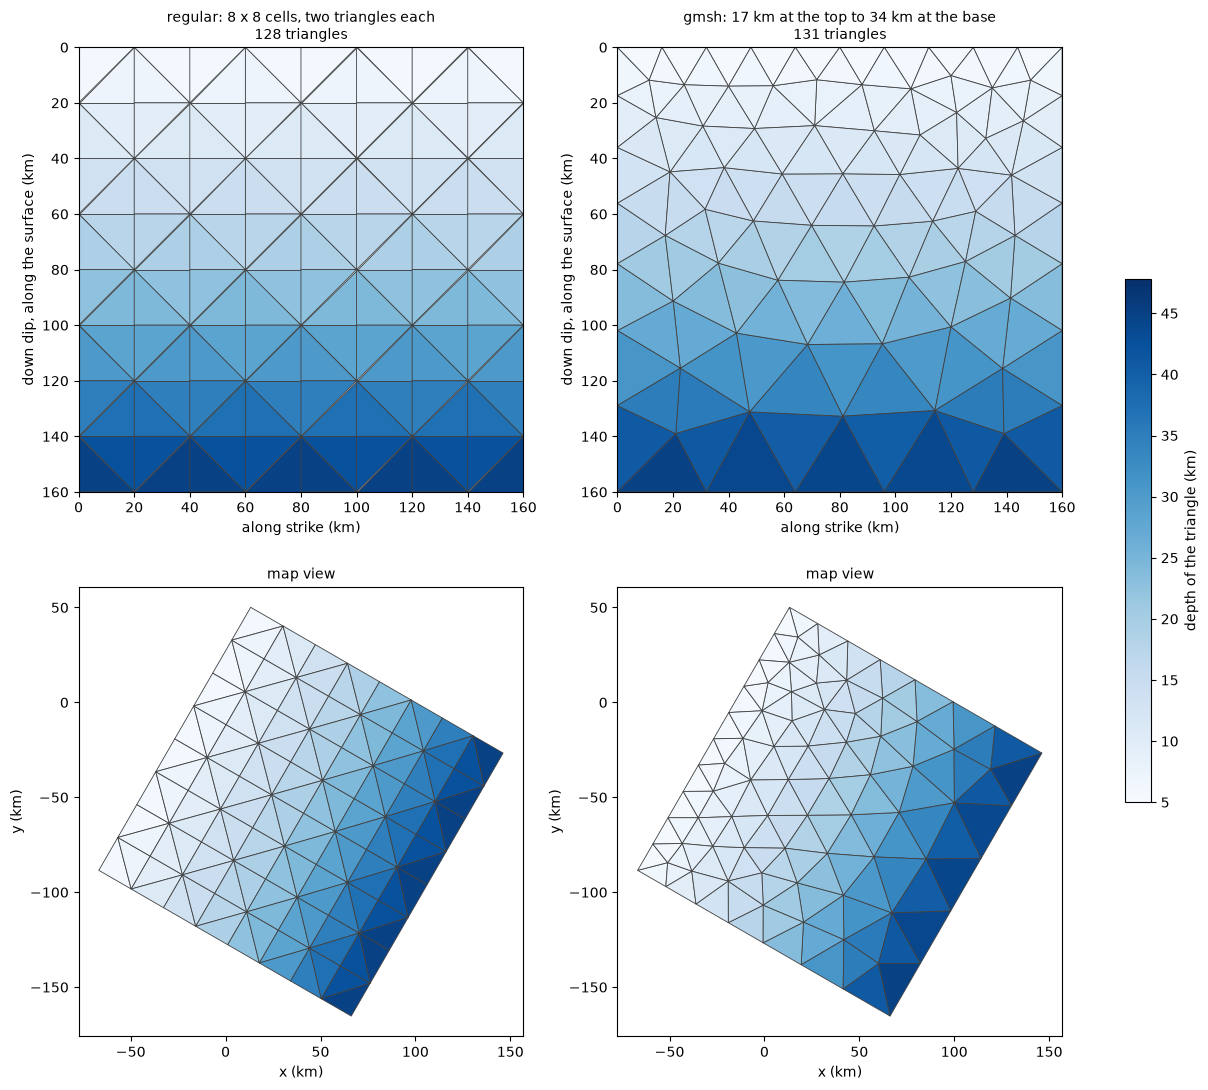

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11), layout='constrained')
depths = np.concatenate([fault.Vertices[:, 2], regular.Vertices[:, 2]])
norm = plt.Normalize(depths.min(), depths.max())
for col, (f, title) in enumerate([(regular, 'regular: 8 x 8 cells, two triangles each'), (fault, f'gmsh: {shallow:.0f} km at the top to {deep:.0f} km at the base')]):
    depth = f.Vertices[f.Faces][:, :, 2].mean(1)
    ax = axes[0, col]
    pc = ax.tripcolor(f.uv[:, 0], f.uv[:, 1], f.Faces, facecolors=depth, cmap='Blues', norm=norm, edgecolors='0.25', lw=0.6)
    ax.set_aspect('equal'); ax.set_xlim(0, length); ax.set_ylim(width, 0)
    ax.set_xlabel('along strike (km)'); ax.set_ylabel('down dip, along the surface (km)')
    ax.set_title(f'{title}\n{len(f.Faces)} triangles', fontsize=10)
    ax = axes[1, col]
    ax.tripcolor(f.Vertices[:, 0], f.Vertices[:, 1], f.Faces, facecolors=depth, cmap='Blues', norm=norm, edgecolors='0.25', lw=0.6)
    ax.set_aspect('equal'); ax.set_xlabel('x (km)'); ax.set_ylabel('y (km)'); ax.set_title('map view', fontsize=10)
fig.colorbar(pc, ax=axes, shrink=0.5, label='depth of the triangle (km)')
plt.show()

## Rakes, source points and stations

As in kinematic_mesh: the slip of each patch has a component along the convergence of the Nazca plate, N83°E, and one across it, and each patch carries source points, 3 along each edge. The stations are kinematic_mesh's, placed with the source points of its regular mesh and the same random generator, so both examples see the same stations, and, further down, the same noise: 18 waveform stations, 30 GPS and 98 line-of-sight points, on land. A few now lie above source points of the new mesh, which is harmless, as the sources are at least 5 km deep.

In [4]:
parallel = fault.convergenceRakes(83.0)
rakes = (parallel + 90.0, parallel)
fault.setSourcePoints(3)
regular.setSourcePoints(3)
Np = len(fault.patch)
print(f"{Np} patches, {len(fault.sources_xyz)} source points")

rng = np.random.default_rng(2016)
coast = 45.0
sources = regular.sources_xyz[:, :2]
point = lambda a, c: (x0 + a * np.sin(phi) + c * np.cos(phi), y0 + a * np.cos(phi) - c * np.sin(phi))

def land(count, near, far, spread=20.0):
    # {count} places on land, {near} to {far} km east of the coast, at least 1 km from the regular mesh's sources
    places = []
    while len(places) < count:
        a, c = rng.uniform(-spread, length + spread), coast + rng.uniform(near, far)
        x, y = point(a, c)
        if np.hypot(sources[:, 0] - x, sources[:, 1] - y).min() >= 1.0:
            places.append((x, y))
    return np.array(places)

def stations(name, places, prefix):
    data = csi.seismic(name, lon0=-80.0, lat0=0.0)
    data.setStat([f"{prefix}{k:03d}" for k in range(len(places))], *fault.xy2ll(places[:, 0], places[:, 1]), loc_format="LL")
    return data

kinematic = stations("kinematic", land(18, 2.0, 120.0), "K")
gps = stations("gps", land(30, 2.0, 150.0), "G")
ga, gc = np.meshgrid(np.linspace(-10, 170, 12), coast + np.linspace(3, 100, 10), indexing="ij")
insar_xy = np.array([point(a, c) for a, c in zip(ga.ravel(), gc.ravel())])
insar_xy = insar_xy[[np.hypot(sources[:, 0] - x, sources[:, 1] - y).min() >= 1.0 for x, y in insar_xy]]
insar = stations("insar", insar_xy, "I")
print(f"{len(kinematic.sta_name)} waveform stations, {len(gps.sta_name)} gps, {len(insar.sta_name)} line of sight points")

131 patches, 1179 source points
18 waveform stations, 30 gps, 98 line of sight points


## The Green's functions

The same engine and settings as kinematic_mesh: seismograms of the pyrocko store `crust2_2hz_d0` for a unit slip of each patch along each rake, bandpassed at 0.015 to 0.08 Hz, and the static offsets from the same store.

In [5]:
engine = csi.pyrockoengine("crust2_2hz_d0", store_dir, delta=1.0)
fault.setMu(engine.material)
start = time.perf_counter()
fault.buildKinGFs(kinematic, engine, Dt=1.0, npts=160, rakes=rakes, points=True, bandpass=(0.015, 0.08))
fault.buildBigGD(kinematic, Nt=85, Dt=1.0)
Ggps = fault.buildStaticGFs(gps, engine, rakes=rakes, points=True)
Gins = fault.buildStaticGFs(insar, engine, rakes=rakes, points=True)
los = np.array([0.62, -0.11, 0.78])  # east, north, up: a descending track
Glos = np.einsum("c,scp->sp", los, Gins.reshape(len(insar.sta_name), 3, -1))
print(f"{time.perf_counter() - start:.0f} s; big G {fault.bigG.shape}, gps {Ggps.shape}, line of sight {Glos.shape}")

126 s; big G (8640, 22270), gps (90, 262), line of sight (98, 262)


## The true rupture

The true model is kinematic_mesh's, the same functions of the centroids of the patches in surface coordinates: a 3 m asperity next to the hypocenter in the north, a 6 m one 70 km south, slip across the convergence of up to 0.3 m, rise times of 4 to 10 s with the slip, and a rupture velocity for each block of 40 x 40 km, 1.98 to 2.99 km/s. On the graded mesh, the blocks hold 3 to 15 triangles: few at depth, where the triangles are large.

In [6]:
uvc = np.array([uv[f].mean(0) for f in F])
a = np.exp(-((uvc - [118.0, 60.0]) ** 2).sum(1) / (2 * 15.0 ** 2))
b = np.exp(-((uvc - [55.0, 75.0]) ** 2).sum(1) / (2 * 18.0 ** 2))
slip_parallel = 0.2 + 3.0 * a + 6.0 * b
slip_across = 0.3 * (a - b)
risetime = 4.0 + 6.0 * (slip_parallel - slip_parallel.min()) / (slip_parallel.max() - slip_parallel.min())
hypocenter = np.array([125.0, 55.0])
blocks = np.clip((uvc / 40.0).astype(int), 0, 3)
groups = blocks[:, 0] * 4 + blocks[:, 1]
centers = np.array([uvc[groups == g].mean(0) for g in range(16)])
velocity = 2.2 + 0.6 * centers[:, 0] / 160.0 + 0.3 * np.sin(centers[:, 1] / 30.0)
print(f"velocity groups of {np.bincount(groups).min()} to {np.bincount(groups).max()} patches; velocities {velocity.min():.2f} to {velocity.max():.2f} km/s")

# AlTar's inputs: the mesh, the hypocenter and the velocity groups, the big G, and the true parameters
os.makedirs('input', exist_ok=True)
os.chdir('input')
fault.setHypoOnFault(*hypocenter)
fault.bigD = np.zeros(fault.bigG.shape[0])
fault.saveKinematic('mesh.h5')
with h5py.File('mesh.h5', 'a') as h5:
    h5['groups/velocity'] = groups
np.savetxt('truth.txt', np.concatenate([slip_across, slip_parallel, risetime, velocity, hypocenter])[None, :])
os.chdir('..')

velocity groups of 3 to 15 patches; velocities 1.98 to 2.99 km/s


The slip history of the true model comes from AlTar's kinematic model, run forward on the true parameters, as in kinematic_mesh:

In [7]:
!slipmodel.plexus forward --config=synthetic.pfg > input/synthetic.log 2>&1

In [8]:
Nt, dt = 85, 1.0
tk = np.arange(Nt) * dt
with h5py.File('input/truth.forward.h5') as h5:
    Mb = np.asarray(h5['Mb/mean_model']).reshape(Nt, 2, Np)
moment = (fault.mu * np.asarray(fault.area) * 1e6 * np.hypot(slip_across, slip_parallel)).sum()
print(f"Mw {2 / 3 * (np.log10(moment) - 9.1):.3f}")

Mw 7.899


## The rupture times on the graded mesh

The rupture front comes from the eikonal equation on the fault, solved on a refinement of the mesh: each patch cut into 10 x 10 triangles, by the fast iterative method. CSI's `castbigM` makes the same slip history from the slips, rise times and velocities of the patches, by AlTar's compiled model when AlTar is installed, or else by fim-python. AlTar's engine reproduces the forward run exactly; fim-python's solver, which matches AlTar's on the regular mesh's right triangles, differs from it slightly on general triangles.

In [9]:
fault.slip[:, 0], fault.slip[:, 1] = slip_across, slip_parallel
fault.tr, fault.vr = risetime, velocity[groups]
for engine_name in ['altar', 'fim']:
    M = fault.castbigM(Nt, dt, engine=engine_name).reshape(Nt, 2, Np)
    print(f"castbigM by {engine_name}: against AlTar's forward run, {np.abs(M - Mb).max() / np.abs(Mb).max():.1e} of its largest value")

castbigM by altar: against AlTar's forward run, 0.0e+00 of its largest value


castbigM by fim: against AlTar's forward run, 7.4e-03 of its largest value


Both solvers are first order: the times are linear across each small triangle, while the true time from a point hypocenter, its distance over the velocity, is a cone, which a chord overestimates. The fronts arrive a little late, by an amount set near the hypocenter, where the front curves most, and carried outward. On this slab the exact times are known: at a constant velocity, the straight distance in surface coordinates over the velocity. Against them, by refinement, on both meshes:

In [10]:
print(f"{'mesh':>8s} {'refine':>6s} {'spacing':>8s}   late, mean / max: {'fim-python':>13s} {'AlTar':>13s}")
for name, f in [('regular', regular), ('gmsh', fault)]:
    f.setHypoOnFault(*hypocenter)
    f.vr = np.full(len(f.patch), 2.5)
    exact = np.linalg.norm(f.sources_uv - hypocenter, axis=1) / 2.5
    for refine in [5, 10, 20, 40]:
        row = []
        for engine_name in ['fim', 'altar']:
            f.computeRuptureTimes(refine=refine, engine=engine_name)
            late = f.sources_t0 - exact
            row.append(f"{late.mean():.2f} / {late.max():.2f} s")
        print(f"{name:>8s} {refine:6d} {f.rupture_mesh['spacing']:6.2f} km   {'':18s} {row[0]:>13s} {row[1]:>13s}")

    mesh refine  spacing   late, mean / max:    fim-python         AlTar
 regular      5   4.55 km                      0.48 / 0.97 s 0.48 / 0.97 s


 regular     10   2.28 km                      0.30 / 0.62 s 0.30 / 0.62 s


 regular     20   1.14 km                      0.16 / 0.40 s 0.16 / 0.40 s


 regular     40   0.57 km                      0.09 / 0.24 s 0.09 / 0.24 s
    gmsh      5   4.17 km                      0.53 / 0.86 s 0.48 / 0.79 s


    gmsh     10   2.09 km                      0.28 / 0.52 s 0.27 / 0.46 s


    gmsh     20   1.04 km                      0.16 / 0.28 s 0.16 / 0.28 s


    gmsh     40   0.52 km                      0.10 / 0.18 s 0.09 / 0.18 s


The lateness halves with the spacing, and the two solvers converge to the same times: it is the discretization, not the solver. At the default refinement, it is about 0.3 s, under 1% of the arrival times beyond 40 s; the graded mesh is as accurate as the regular one. In these synthetic tests it cancels, as the truth and the inversion share the solver; on real data, it would be absorbed by a slightly faster rupture velocity.

## The data

The waveforms, the GPS offsets and the line of sight of the true model, with kinematic_mesh's noise: 5 mm on the waveforms and the GPS, 1 cm on the line of sight.

waveforms: peak 40.2 cm; gps: peak 114.1 cm; line of sight: -95.2 to 2.2 cm


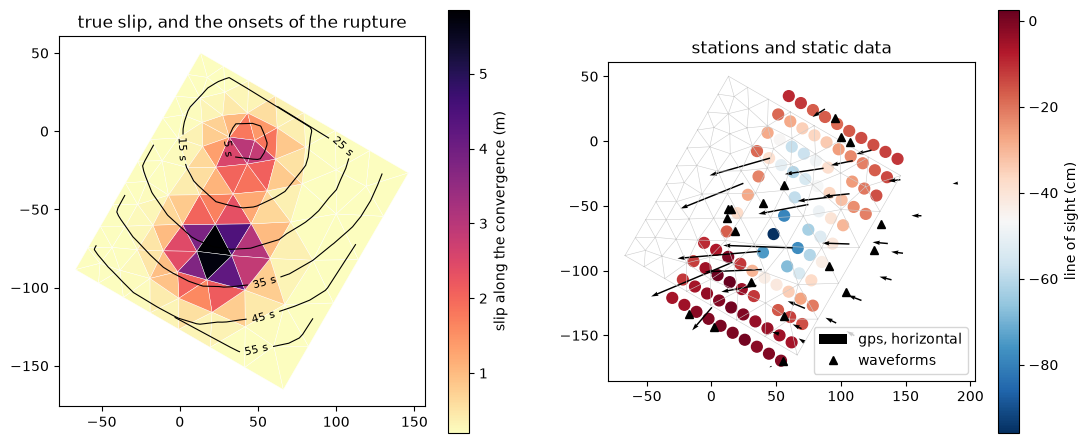

In [11]:
waveforms = fault.bigG @ Mb.ravel()
final = np.concatenate([slip_across, slip_parallel])
sigma = {'waveforms': 0.005, 'gps': 0.005, 'line of sight': 0.01}
d_waveforms = waveforms + sigma['waveforms'] * rng.standard_normal(waveforms.size)
d_gps = Ggps @ final + sigma['gps'] * rng.standard_normal(Ggps.shape[0])
d_los = Glos @ final + sigma['line of sight'] * rng.standard_normal(Glos.shape[0])
print(f"waveforms: peak {100 * np.abs(waveforms).max():.1f} cm; gps: peak {100 * np.abs(Ggps @ final).max():.1f} cm; "
      f"line of sight: {100 * (Glos @ final).min():.1f} to {100 * (Glos @ final).max():.1f} cm")

# the mean onset of each patch: the centroid time of its slip, less half its rise time
patch_onset = (tk[:, None] * Mb[:, 1]).sum(0) / Mb[:, 1].sum(0) - risetime / 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
pc = ax1.tripcolor(V[:, 0], V[:, 1], F, facecolors=slip_parallel, cmap='magma_r', edgecolors='w', lw=0.3)
fig.colorbar(pc, ax=ax1, label='slip along the convergence (m)')
centroids = V[F].mean(1)
cs = ax1.tricontour(centroids[:, 0], centroids[:, 1], patch_onset, levels=np.arange(5, 75, 10), colors='k', linewidths=0.8)
ax1.clabel(cs, fmt='%d s', fontsize=8)
ax1.set_aspect('equal'); ax1.set_title('true slip, and the onsets of the rupture')
gx, gy = fault.ll2xy(np.asarray(gps.lon), np.asarray(gps.lat))
ix, iy = fault.ll2xy(np.asarray(insar.lon), np.asarray(insar.lat))
kx, ky = fault.ll2xy(np.asarray(kinematic.lon), np.asarray(kinematic.lat))
sc = ax2.scatter(ix, iy, c=100 * d_los, cmap='RdBu_r', s=60)
fig.colorbar(sc, ax=ax2, label='line of sight (cm)')
o = d_gps.reshape(-1, 3)
ax2.quiver(gx, gy, o[:, 0], o[:, 1], scale=5, width=0.004, label='gps, horizontal')
ax2.plot(kx, ky, 'k^', label='waveforms')
ax2.triplot(V[:, 0], V[:, 1], F, color='0.8', lw=0.4)
ax2.set_aspect('equal'); ax2.set_title('stations and static data'); ax2.legend(loc='lower right')
plt.show()

## The files for AlTar

The same layout as kinematic_mesh's: the mesh and the big G from `saveKinematic`, the waveforms, the static Green's functions, data and covariance, and the truth, for step 2.

In [12]:
os.chdir('input')
with h5py.File('kinematicG.data.h5', 'w') as h5:
    h5['kinematicG.data'] = d_waveforms
d_static = np.concatenate([d_gps, d_los])
sigma_static = np.concatenate([np.full(d_gps.size, sigma['gps']), np.full(d_los.size, sigma['line of sight'])])
for name, values in [('static.gf', np.vstack([Ggps, Glos])), ('static.data', d_static), ('static.Cd', np.diag(sigma_static ** 2))]:
    with h5py.File(f'{name}.h5', 'w') as h5:
        h5[name] = values
with h5py.File('synthetic.h5', 'w') as h5:
    for name, values in [('across', slip_across), ('parallel', slip_parallel), ('risetime', risetime),
                         ('rupturevelocity', velocity), ('hypocenter', hypocenter)]:
        h5[f'true/{name}'] = values
    h5['true/Mb'] = Mb
    h5['mu'], h5['area'], h5['dt'] = fault.mu, np.asarray(fault.area), dt
    h5['stations'] = np.array(kinematic.sta_name, dtype='S')
for name in sorted(n for n in os.listdir('.') if n.endswith('.h5')):
    print(f"{name}: {os.path.getsize(name) / 1e6:.3g} MB")
os.chdir('..')

kinematicG.data.h5: 0.0712 MB
kinematicG.gf.h5: 1.54e+03 MB
mesh.h5: 0.045 MB
static.Cd.h5: 0.285 MB
static.data.h5: 0.00355 MB
static.gf.h5: 0.396 MB
synthetic.h5: 0.191 MB
truth.forward.h5: 1.11 MB
